In [1]:
from typing import TypedDict

from langchain_openai import ChatOpenAI
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph import END, START, StateGraph

In [2]:
llm = ChatOpenAI(
    base_url='http://127.0.0.1:9931/v1',
    model='local qwen3.5:4b',
    api_key='not needed'
)

In [3]:
class JokeState(TypedDict):
    topic: str
    joke: str
    explanation: str

In [4]:
def generate_joke(state: JokeState):
    prompt = f'generate a single joke on the topic {state["topic"]}'
    response = llm.invoke(prompt).content

    return {'joke': response}


def generate_explanation(state: JokeState):
    prompt = f'write a 40 word explanation for the joke - {state["joke"]}'
    response = llm.invoke(prompt).content

    return {'explanation': response}

In [5]:
graph = StateGraph(JokeState)

graph.add_node('generate_joke', generate_joke)
graph.add_node('generate_explanation', generate_explanation)

graph.add_edge(START, 'generate_joke')
graph.add_edge('generate_joke', 'generate_explanation')
graph.add_edge('generate_explanation', END)

checkpointer = InMemorySaver()
workflow = graph.compile(checkpointer=checkpointer)

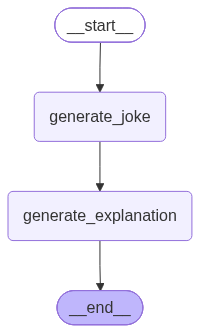

In [6]:
workflow

For persistence, pass thread id during invocation of workflow

In [7]:
config1 = {'configurable': {'thread_id': '1'}}
workflow.invoke({'topic': 'Helmet'}, config=config1)

{'topic': 'Helmet',
 'joke': "Why don't helmets ever play hide and seek?\nBecause they always stick their head in the sand!",
 'explanation': "Helmets always stick their head in the sand when playing hide and seek, which is a common idiom describing someone ignoring obvious problems. The joke relies on this pun, making the helmet's literal action fit the figurative phrase perfectly."}

In [8]:
workflow.get_state(config=config1)

StateSnapshot(values={'topic': 'Helmet', 'joke': "Why don't helmets ever play hide and seek?\nBecause they always stick their head in the sand!", 'explanation': "Helmets always stick their head in the sand when playing hide and seek, which is a common idiom describing someone ignoring obvious problems. The joke relies on this pun, making the helmet's literal action fit the figurative phrase perfectly."}, next=(), config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1cbc62-76f9-6bfb-8002-88096480d3e7'}}, metadata={'source': 'loop', 'step': 2, 'parents': {}}, created_at='2026-10-19T14:05:35.078489+00:00', parent_config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1cbc62-63c1-6d40-8001-5fdc80ee60d4'}}, tasks=(), interrupts=())

In [11]:
list(workflow.get_state_history(config=config1))

[StateSnapshot(values={'topic': 'Helmet', 'joke': "Why don't helmets ever play hide and seek?\nBecause they always stick their head in the sand!", 'explanation': "Helmets always stick their head in the sand when playing hide and seek, which is a common idiom describing someone ignoring obvious problems. The joke relies on this pun, making the helmet's literal action fit the figurative phrase perfectly."}, next=(), config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1cbc62-76f9-6bfb-8002-88096480d3e7'}}, metadata={'source': 'loop', 'step': 2, 'parents': {}}, created_at='2026-10-19T14:05:35.078489+00:00', parent_config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1cbc62-63c1-6d40-8001-5fdc80ee60d4'}}, tasks=(), interrupts=()),
 StateSnapshot(values={'topic': 'Helmet', 'joke': "Why don't helmets ever play hide and seek?\nBecause they always stick their head in the sand!"}, next=('generate_explanation',), config={'configurable

In [15]:
config2 = {'configurable': {'thread_id': '2'}}
workflow.invoke({'topic': 'hat'}, config=config2)

{'topic': 'hat',
 'joke': "Why don't hats ever get invited to parties?\nBecause they always wear themselves out.",
 'explanation': 'This joke plays on wordplay by equating "wearing themselves out" with the act of putting on a hat. Just as people fatigue from exercise, hats are literally worn until they become worn, so they cannot attend social gatherings.'}

In [16]:
list(workflow.get_state_history(config2))

[StateSnapshot(values={'topic': 'hat', 'joke': "Why don't hats ever get invited to parties?\nBecause they always wear themselves out.", 'explanation': 'This joke plays on wordplay by equating "wearing themselves out" with the act of putting on a hat. Just as people fatigue from exercise, hats are literally worn until they become worn, so they cannot attend social gatherings.'}, next=(), config={'configurable': {'thread_id': '2', 'checkpoint_ns': '', 'checkpoint_id': '1f1cbca2-be40-691f-8006-bcfcd64f026d'}}, metadata={'source': 'loop', 'step': 6, 'parents': {}}, created_at='2026-10-19T14:34:20.539305+00:00', parent_config={'configurable': {'thread_id': '2', 'checkpoint_ns': '', 'checkpoint_id': '1f1cbca2-a998-6bbc-8005-be645ea1f110'}}, tasks=(), interrupts=()),
 StateSnapshot(values={'topic': 'hat', 'joke': "Why don't hats ever get invited to parties?\nBecause they always wear themselves out.", 'explanation': 'Capers are a type of celery flower that has no roots, so they cannot get lost